# Branded Newsletter Visuals

If you're any kind of digital creative, chances are you need to create new visuals every time you create any kind of content.

Rami Krispin publishes a weekly [data newsletter](https://ramikrispin.substack.com/archive) on Substack and LinkedIn. Every issue features a fancy cover image. LinkedIn supports video, so there he posts a short trailer instead. Each one carries his newsletter's branding and the issue number.

If you make visuals this often, you'll want a system for it. You'll want to store your prompts, and ideally version them. You'll want to store what the models make, without getting crafty with file names. Most of all, you'll want to see it all together, in one place.

Today we'll build that system in Pixeltable. Every new issue is a new row in a database, and every new issue gets the same treatment: custom but templated prompts that generate on-brand static images and trailers.

Importantly, the system is one you own, so your prompts, images, and trailers live in your own database, not scattered across chat histories and a downloads folder.

<video src="images/video-111.mp4" poster="images/cover-111.png" controls width="100%"></video>

This is issue 111. Gemini painted the picture and made the video. Python drew the words.

It takes three steps, and all three live in one table.

## Setup

Start Jupyter with `uv run jupyter lab` in this folder. Put your Gemini key in `~/.pixeltable/config.toml`.

In the same file, set Omni's rate limit to four a minute. The README shows the line.

This first cell clears out anything from an earlier run.

In [ ]:
import pixeltable as pxt

# Start fresh: drop the table from any earlier run.
pxt.drop_dir('visuals', force=True, if_not_exists='ignore')

Connected to Pixeltable database at: postgresql+psycopg://postgres:***@/pixeltable?host=%2FUsers%2Falison-pxt%2F.pixeltable%2Fpgdata


## We fill in two columns, and Pixeltable computes the rest

In Pixeltable, you declare your table in a Python file. Here's the top of ours.

In [ ]:
!sed -n '45,49p' schema.py

class Issues(TableModel, name='issues'):
    issue_number = pxt.Column(type=pxt.Int, primary_key=True)
    scene: pxt.String
    # Optional: a picture for Nano Banana to start from. Leave it out for text only.
    inspiration: pxt.Image | None


We fill in two columns, the issue number and the scene. The scene is one sentence about the picture.

The inspiration column is optional. It holds a picture for Nano Banana to start from. Nano Banana is Gemini's image model.

The issue number is the primary key. If you insert the same issue twice, you get an error instead of a copy.

## Step 1: The scene goes into a prompt, and Nano Banana paints the picture

The scene goes into a prompt template. Here's the template for the picture.

In [ ]:
!sed -n '24,30p' schema.py

# Fills {image_note} only when the row has an inspiration image. Without one, {image_note} is empty.
INSPIRATION_NOTE = 'Use the attached image as inspiration. '
# The scene you type goes into both prompts.
ART_TEMPLATE = (
    '{image_note}{scene} The picture fills the whole wide image edge to edge, with no frame, border, margins, '
    'or empty bands. No text, no letters, no numbers, no watermark.'
)


Everything else in it is the same for every issue.

If the row has an inspiration image, we put a note in front. The note tells Nano Banana to use it.

Here's where the table fills in that template.

In [ ]:
!sed -n '51,53p' schema.py

    issue_label = pxtf.string.format('ISSUE {issue_number}', issue_number=issue_number)
    image_note = udfs.note_if_image(inspiration, INSPIRATION_NOTE)
    art_prompt = pxtf.string.format(ART_TEMPLATE, image_note=image_note, scene=scene)


`issue_label` turns the number into the words for the cover.

`note_if_image` is a UDF. That's a Python function Pixeltable can call on every row. It adds the note only when there's an image.

No model runs here. `string.format` fills in the template for each row. Every row gets its own `art_prompt`.

The art prompt goes to Nano Banana.

In [ ]:
!sed -n '56,62p' schema.py

    # Nano Banana gets the inspiration image, if there is one, and then the prompt.
    art_response = pxtf.gemini.generate_content(
        udfs.art_input(art_prompt, inspiration),
        model=IMAGE_MODEL,
        config={'response_modalities': ['IMAGE'], 'image_config': {'aspect_ratio': '16:9'}},
    )
    art = art_response.candidates[0].content.parts[0].inline_data.data.astype(pxt.Image)


The last line pulls the picture out of the response into the `art` column.

## Step 2: Python stamps the words on the picture

Image models still misspell words, so we draw the words ourselves in plain Python.

The newsletter name sits at the top of `udfs.py`. Below it is another UDF, `make_plate`.

In [ ]:
!sed -n '14p;59,61p;97,99p' udfs.py

NEWSLETTER_NAME = "RAMI'S DATA NEWSLETTER"
@pxt.udf
def make_plate(art: pxt.Image, issue_label: pxt.String) -> pxt.Image:
    """Transparent plate the size of the art: a pink neon issue line and a hollow white name with a red glow."""
    plate.paste(_PINK_CORE, (0, 0), full_issue)
    plate.paste(_WHITE, (0, 0), name_ring)
    return plate


`make_plate` draws the issue label and the newsletter name on a clear layer. We call that layer the plate.

In [ ]:
!sed -n '64,65p' schema.py

    plate = udfs.make_plate(art, issue_label)
    cover = udfs.composite_cover(art, plate)


`composite_cover` lays the plate over the art. That's our cover.

## Step 3: Gemini Omni turns the cover into a video

Gemini Omni is Gemini's video model. It gets its own prompt template.

In [ ]:
!sed -n '31,42p' schema.py

MOTION_TEMPLATE = (
    '<FIRST_FRAME> Animate this picture as one 5-second shot, starting on this exact picture. The picture shows: {scene} '
    'The camera pushes in slowly for the whole shot, with no panning. '
    'What is already in the picture comes alive and keeps moving clearly the whole time, in whatever ways fit it: '
    'grass and leaves sway in a breeze, light and shadows shift slowly, '
    'water flows, stars and moons pulse brighter and dimmer. '
    'Every moving element is subtle and realistic but still noticeable, '
    'and each one moves at its own random pace and timing, never in step with the others. '
    'Keep its style and colors. '
    'Add nothing that is not already in the picture. '
    'Keep the pink {issue_label} and the newsletter name exactly where they are, sharp and unchanged.'
)


It tells Omni to start on the cover. It also says to keep the words sharp. The rest is on screen.

Here the table fills in the `motion_prompt`. It uses the same scene and the issue label.

In [ ]:
!sed -n '54p' schema.py

    motion_prompt = pxtf.string.format(MOTION_TEMPLATE, scene=scene, issue_label=issue_label)


Pixeltable calls Omni for us. The video is one more column.

In [ ]:
!sed -n '67,72p' schema.py

    video = pxtf.gemini.generate_video(
        motion_prompt,
        images=[cover],
        model=VIDEO_MODEL,
        config={'aspect_ratio': '16:9', 'duration': f'{VIDEO_SECONDS}s'},
    )


If a call runs past five minutes, Pixeltable stops it. That row gets an error instead of hanging.

## Pixeltable creates the table from the file

Before we change anything, schema diff shows us what's going to change.

In [ ]:
!pxt schema diff schema.py visuals

+ visuals/issues           create

Plan: 1 create, 0 update, 0 unchanged, 0 extra  |  0 destructive


Then schema update makes the change.

In [ ]:
!pxt schema update schema.py visuals -f

created   visuals/issues


The table exists now. No model has run yet, because there are no rows.

## One insert makes issue 111

Here's issue 111. It's a number and a scene, with no inspiration image.

In [ ]:
from sample_issues import ISSUES

issue_111 = [row for row in ISSUES if row['issue_number'] == 111]
issue_111

[{'issue_number': 111,
  'scene': 'A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds.'}]

Each insert makes two paid Gemini calls and takes about 40 seconds. I ran these ahead of time.

With `on_error='ignore'`, one failed call doesn't stop the whole insert. The error stays in its cell. We can look at it like any other data.

In [ ]:
issues = pxt.get_table('visuals.issues')
issues.insert(issue_111, on_error='ignore')

Inserted 1 row with 0 errors in 42.23 s (0.02 rows/s)


1 row inserted.

Here are the two prompts Pixeltable built from our scene.

In [ ]:
issues.select(issues.art_prompt, issues.motion_prompt).collect()

art_prompt,motion_prompt
"A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds. The picture fills the whole wide image edge to edge, with no frame, border, margins, or empty bands. No text, no letters, no numbers, no watermark.","<FIRST_FRAME> Animate this picture as one 5-second shot, starting on this exact picture. The picture shows: A photoreal cinematic wide shot of a lush green mountain valley, a lone tree in the meadow, rocks in the foreground, and a bright sky with large white clouds. The camera pushes in slowly for the whole shot, with no panning. What is already in the picture comes alive and keeps moving clearly the whole time, in whatever ways fit it: grass and leaves sway in a breeze, light and shadows shift slowly, water flows, stars and moons pulse brighter and dimmer. Every moving element is subtle and realistic but still noticeable, and each one moves at its own random pace and timing, never in step with the others. Keep its style and colors. Add nothing that is not already in the picture. Keep the pink ISSUE 111 and the newsletter name exactly where they are, sharp and unchanged."


Our scene is in both of them. Now the cover and the video.

issue_label,cover,video
ISSUE 111,,

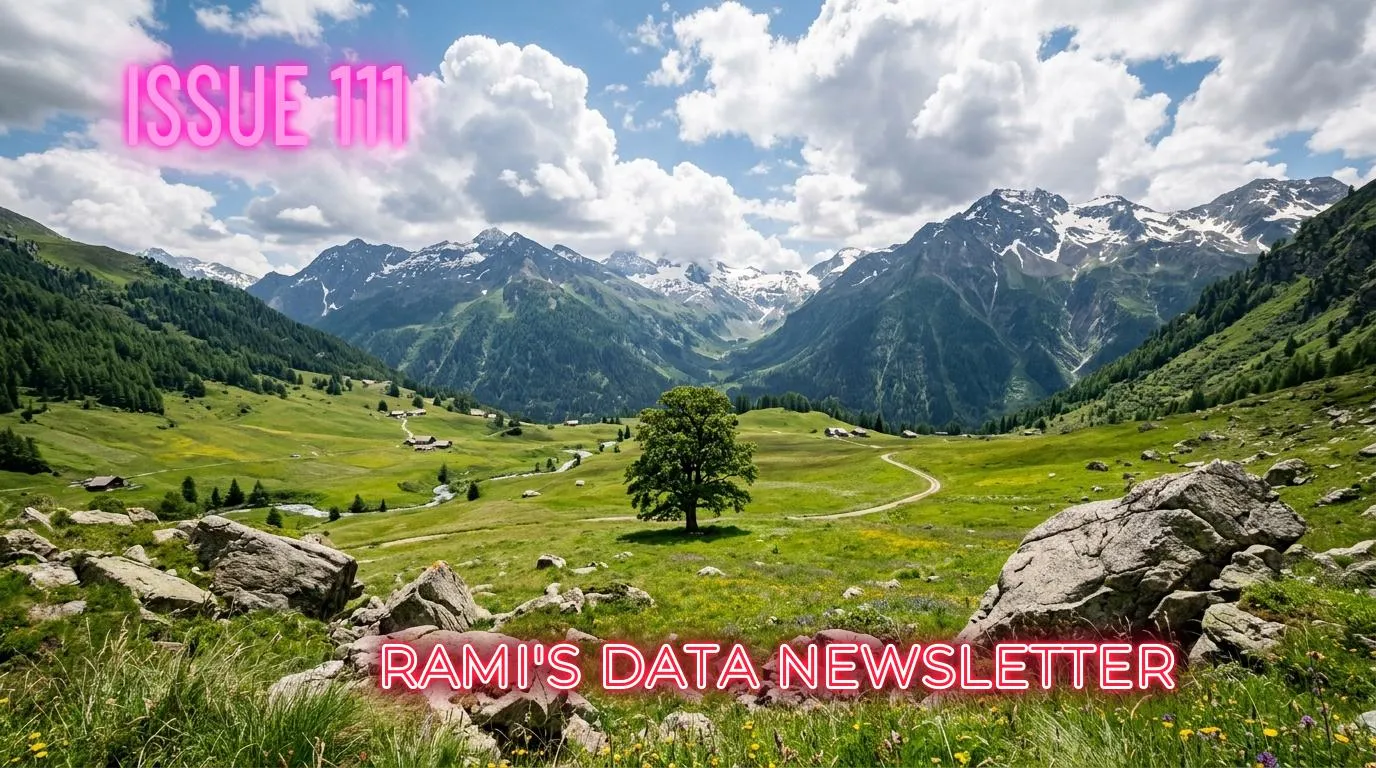
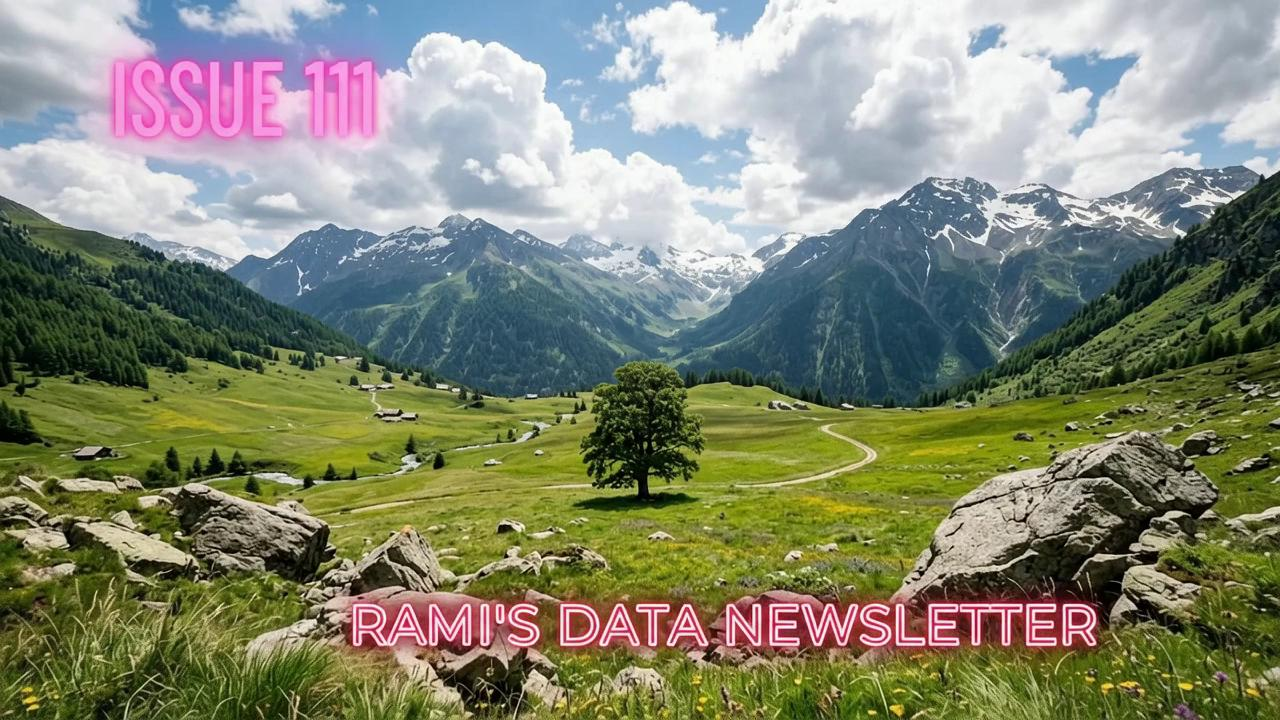

In [ ]:
issues.select(issues.issue_label, issues.cover, issues.video).collect()

The camera moves slowly into the valley, and the clouds drift. The words stay sharp.

Gemini makes a different picture every time. Pixeltable keeps this one with the issue.

## A new issue is one more row

Issue 109 is a Van Gogh night sky over a horse in a wheat field. It's the same insert with a new row.

In [ ]:
issues.insert([row for row in ISSUES if row['issue_number'] == 109], on_error='ignore')

Inserted 1 row with 0 errors in 42.30 s (0.02 rows/s)


1 row inserted.

It says one row inserted. Pixeltable only computed the new row.

Issue 111 kept its cover and its video.

issue_label,cover,video
ISSUE 109,,
ISSUE 111,,

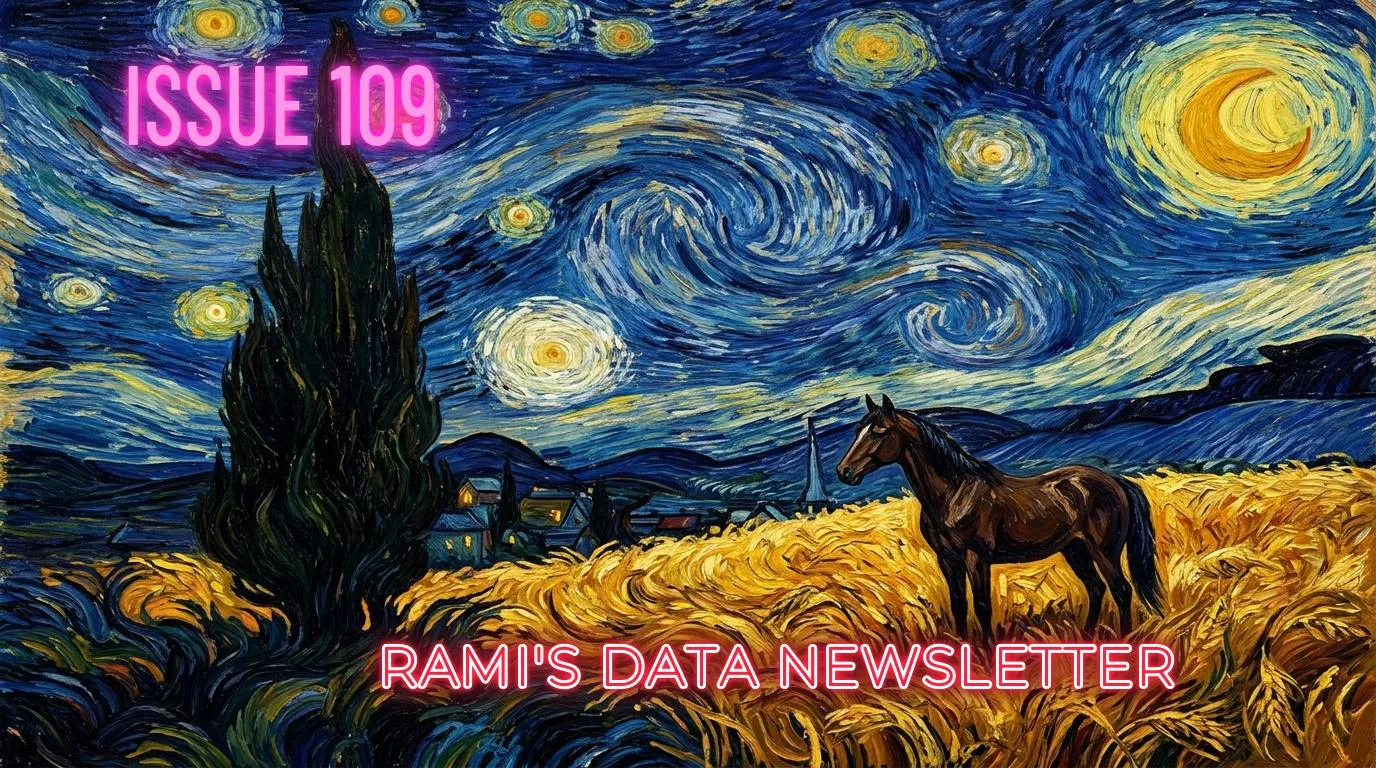
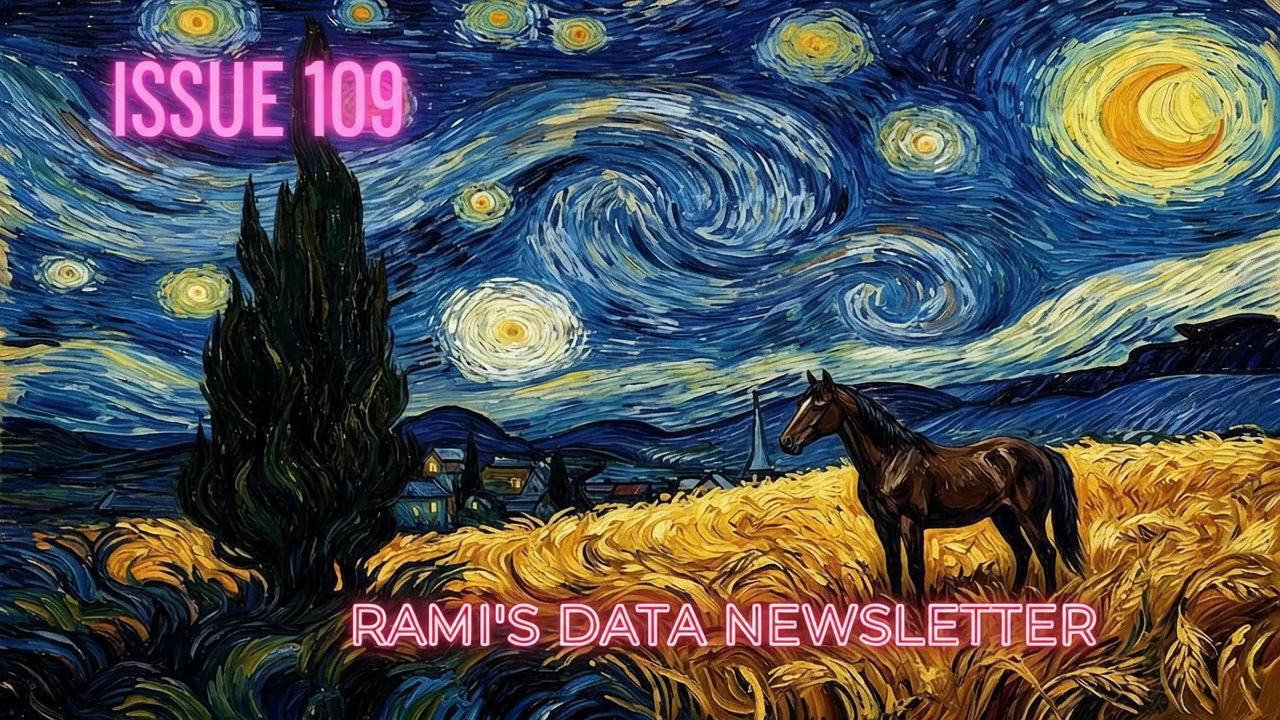
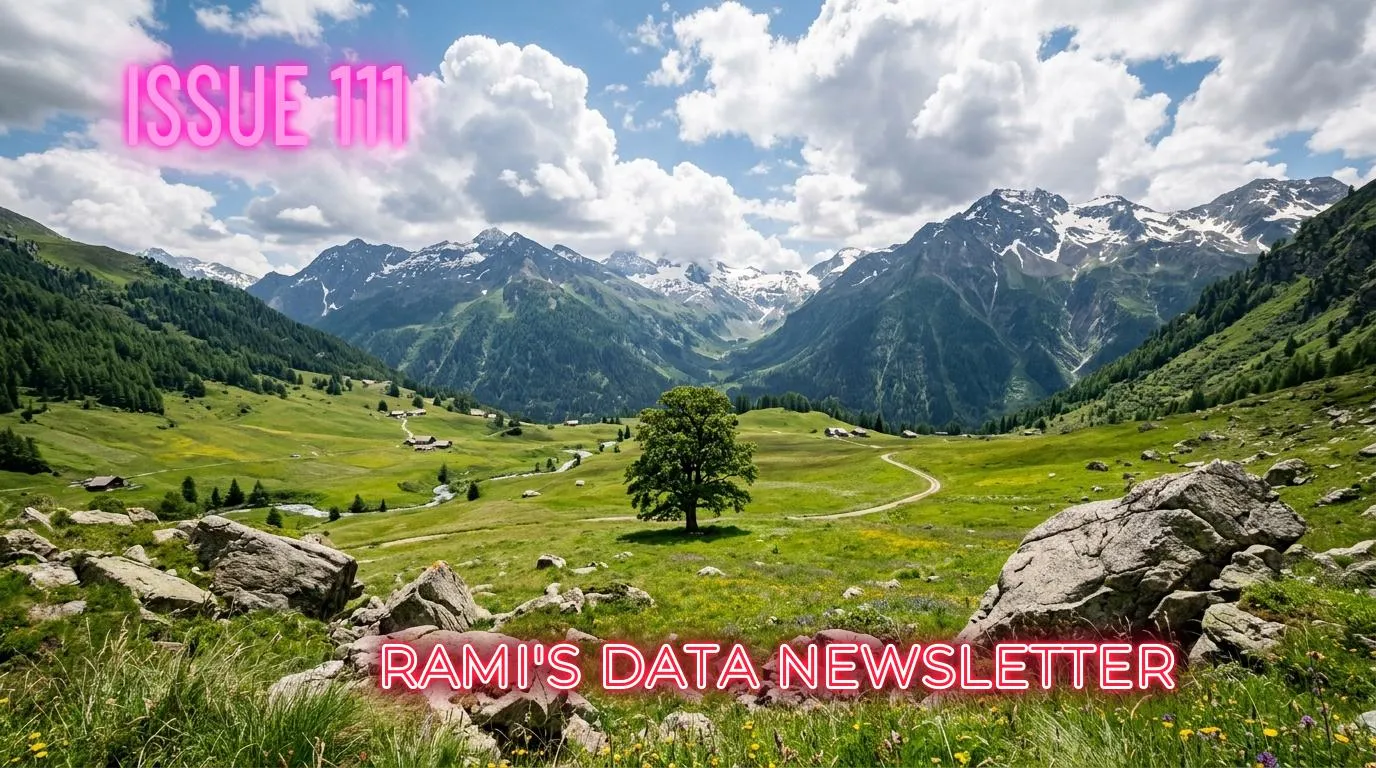
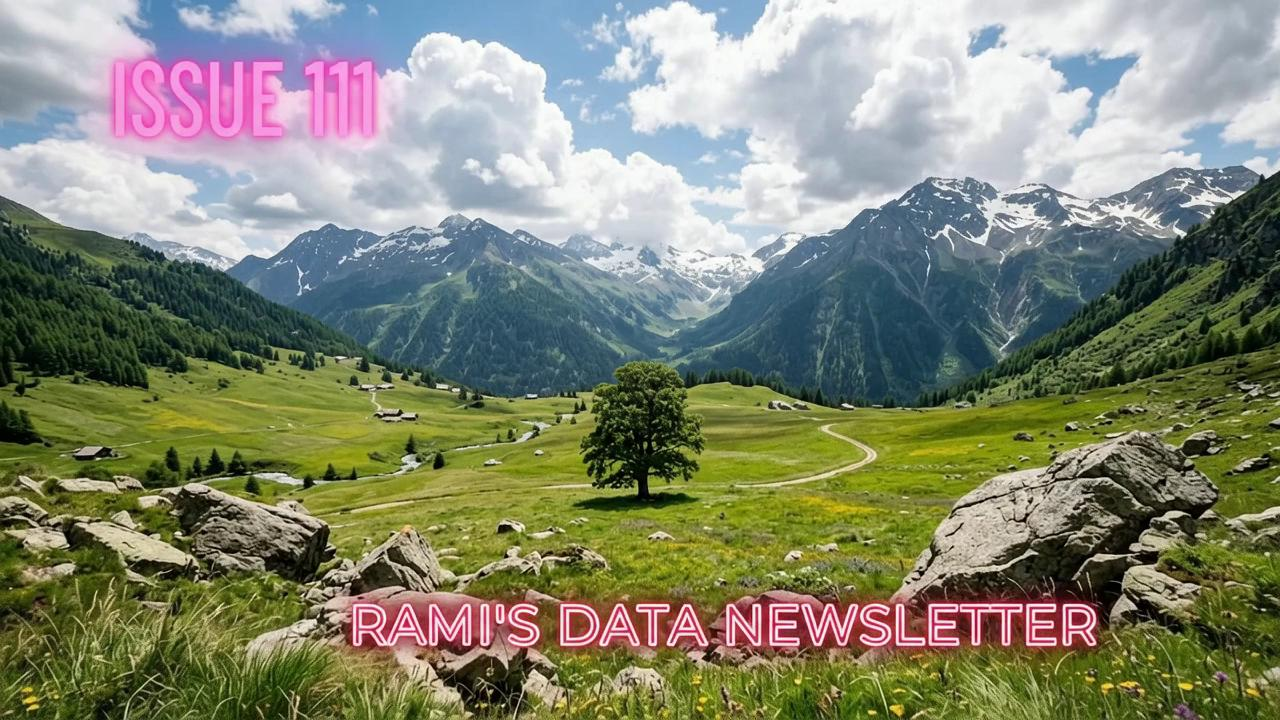

In [ ]:
issues.select(issues.issue_label, issues.cover, issues.video).order_by(issues.issue_number).collect()

The stars twinkle, and the horse turns its head. Omni added a sparkle or two that the painting doesn't have.

I made this video twice. The first take added clouds to the painting. I changed one line of the motion template. Then I recomputed just this video.

## Rerun only the videos that failed

On my account, Omni allows four videos a minute and twenty a day. A video can fail on a rate limit.

When that happens, the row keeps its cover. The error goes in the video cell. We can list those rows.

In [ ]:
issues.where(issues.video.errortype != None).select(
    issues.issue_number, issues.video.errortype, issues.video.errormsg
).collect()

issue_number,video_errortype,video_errormsg


Both videos came through this time, so the list is empty.

`errors_only=True` reruns just the failed videos. We don't pay for those pictures twice.

In [ ]:
issues.recompute_columns('video', errors_only=True)

No rows affected.

Run the list again after this. When it's empty, every issue has its video.

## Wrap up

We built one table. Each insert turns a number and a scene into a cover and a five-second video.

The README shows how to add an inspiration image. To brand your own covers, change the newsletter name in `udfs.py`.